In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

In [ ]:
!pip install xgboost==3.4.1 lightgbm==4.6.0 --quiet

In [ ]:
from google.colab import drive
import os

# 1. Montar Google Drive
drive.mount('/content/drive')

# 2. Indicar la ruta de TU carpeta existente
# (Sustituye 'Nombre_De_Tu_Carpeta' por el nombre exacto de la carpeta en tu Drive)
WORK_DIR = '/content/drive/MyDrive/Colab Notebooks/TFM - MULTIAGENTES'

# 3. Cambiar el directorio de trabajo a esa carpeta
os.chdir(WORK_DIR)

# Confirmación
print(f"Directorio de trabajo activado: {os.getcwd()}")

Mounted at /content/drive
Directorio de trabajo activado: /content/drive/MyDrive/Colab Notebooks/TFM - MULTIAGENTES


# Cargamos dataset e inspeccionamos

In [ ]:
df = pd.read_csv("Churn_Modelling.csv")

# Dataset 100% crudo, tal cual viene de Kaggle
bank_df_agent = df.copy() #será el que guardaremos para pasarselo a los agentes

display(df.head())
display(df.shape)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


(10000, 14)

In [ ]:
print(df.info())
print(df.describe(include='all'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB
None
          RowNumber    CustomerId Surname   CreditScore Geography Gender  \
count   10000

- variable exited: Hay un cierto desbalanceo (aproximadamente 80% se quedan / 20% se van). no usar accuracy como métrica principal, mejor recall precision F1 y AUCROC para clase minoritaria (churn).

- Países (Geography): Hay 3 países representados. Francia es el principal (5.014 clientes).

- Edad (Age): Edad media de ~39 años (rango amplio de 18 a 92 años).

- Saldos nulos (Balance): El 25% de los clientes (o más) tienen un saldo de 0.00 en su cuenta, lo cual es un hallazgo importante para el análisis.


## Descripcion variables:
DEMOGRÁFICAS:

- Edad

- País

- Genero

- EstimatedSalary: Salario anual estimado del cliente (en unidades monetarias/euros). Rango aproximado: 11.58 € a 199.992,48 €.

RELACION CON EL BANCO:
- CreditScore: "nota" o reputación financiera de cara al banco. Puntuación crediticia del cliente (evaluación de riesgo financiero). Rango: 350 a 850 (media de ~650). mide qué tan probable es que pague sus deudas a tiempo.

- Tenure: Antigüedad del cliente en el banco (número de años que lleva con la entidad, de 0 a 10 años).

- Balance: Saldo actual disponible en la cuenta del cliente.

- NumOfProducts: Número de productos financieros que el cliente tiene contratados con el banco (cuentas, préstamos, inversiones, etc., de 1 a 4).

- HasCrCard: Indica si el cliente posee tarjeta de crédito con el banco (1 = Sí, 0 = No). El 70.55% tiene tarjeta.

- IsActiveMember: Indica si el cliente es considerado un miembro activo comercialmente en el banco (1 = Activo, 0 = Inactivo). Alrededor del 51.5% son activos.

OBJETIVO:
- Exited: 1=churn, 0= permanece

# Data cleaning

In [ ]:
# Columnas que no aportan señal predictiva
bank_df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
bank_df

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


# EDA

## Distribucion variable objetivo: Exited

Exited
0    7963
1    2037
Name: count, dtype: int64
Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64


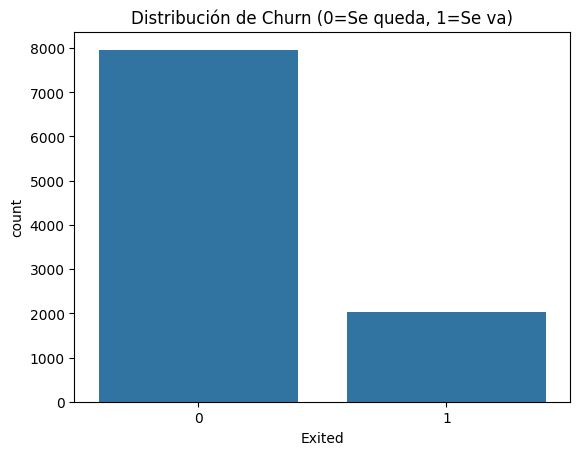

In [ ]:
# Conteo y proporción. 0 se queda, 1 se va (churn)
print(bank_df['Exited'].value_counts())
print(bank_df['Exited'].value_counts(normalize=True))

sns.countplot(data=bank_df, x='Exited')
plt.title('Distribución de Churn (0=Se queda, 1=Se va)')
plt.show()

Observamos el mismo desbalanceo que ya vimos en el describe inicial, casi de 20%/80%.

## Histograma para las variables numéricas y continuas del dataset

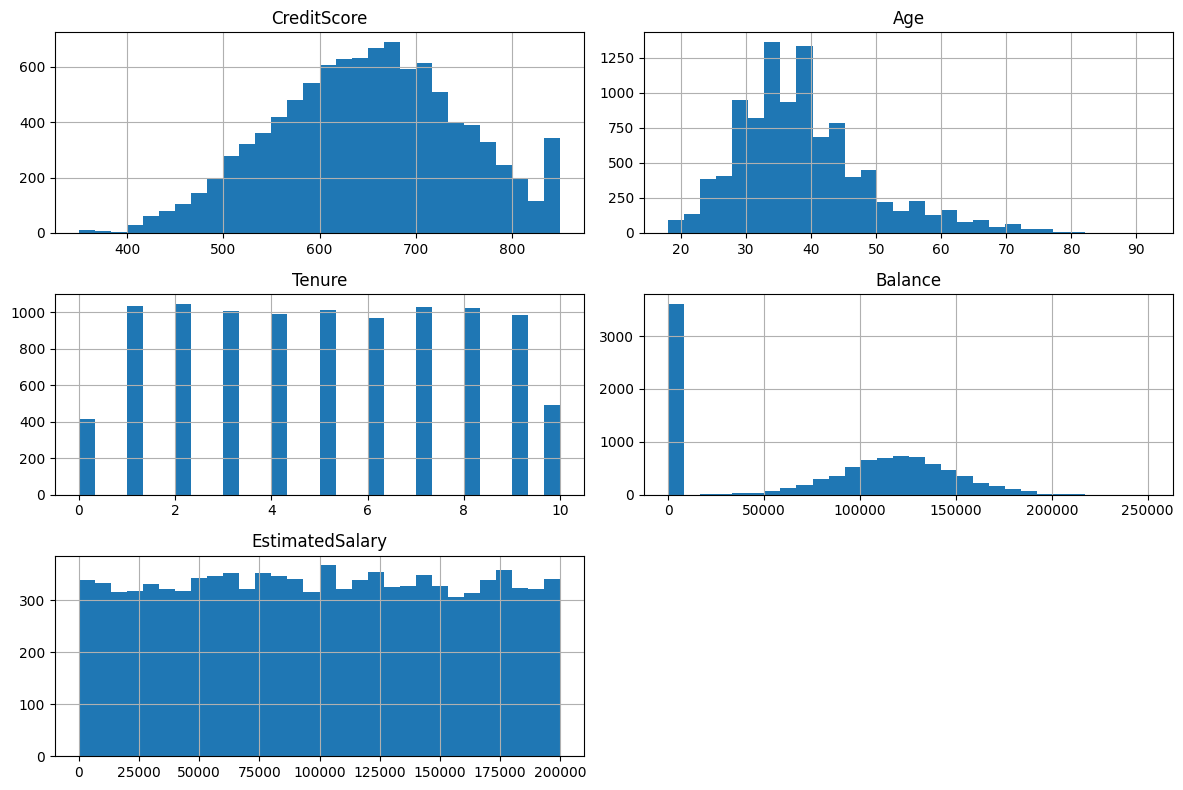

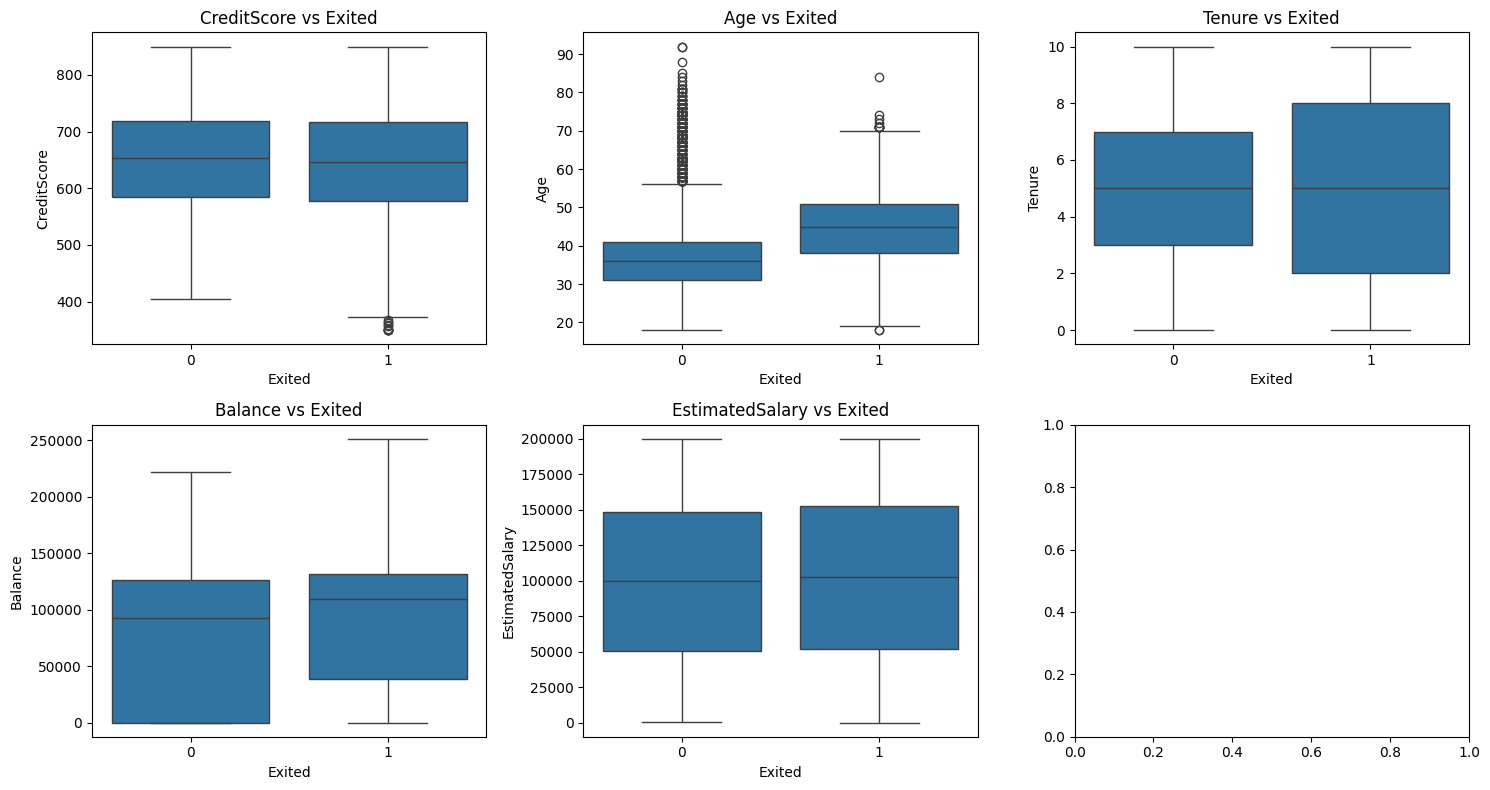

In [ ]:
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']

# Histogramas generales
bank_df[num_cols].hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

# Comparación por Exited (boxplots)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(data=bank_df, x='Exited', y=col, ax=axes[i])
    axes[i].set_title(f'{col} vs Exited')
plt.tight_layout()
plt.show()

- CreditScore: distribución razonablemente normal, ligero pico raro en el extremo derecho (~850) — probablemente un tope/cap del score. El dataset contará con muchos clientes de creditscore máximo (clientes buenos).
- Age: sesgada a la derecha (cola larga hacia edades altas), con un pico partido alrededor de 35-40. Podría ser una mezcla de dos subpoblaciones, es dcir, mezcla de dos perfiles de cliente.
- Tenure: prácticamente uniforme entre 0 y 10, salvo los extremos (0 y 10) con menos frecuencia. No aporta mucha señal por sí sola probablemente.
- Balance: el pico enorme en 0, muchísimos clientes con saldo cero, y el resto sigue una distribución casi normal centrada en ~120k.
- EstimatedSalary: distribución uniforme.

En cuanto los boxplots,

**Age vs Exited** la señal más clara del conjunto
Mediana de Exited=0 (se queda): ~36 años.
Mediana de Exited=1 (se va): ~45 años.
Las cajas casi no se solapan — la caja de los que se van (25-75%) empieza justo donde termina la mitad superior de los que se quedan. **Los clientes mayores tienen mucha más tendencia al churn.** También hay muchos outliers en Exited=0 en la parte alta (clientes mayores que no obstante se quedan) — algo normal, no un error de datos.

**Balance vs Exited**
la caja de Exited=0 empieza en 0 coherente con que muchos de los que se quedan tienen balance cero.

## Variables categóricas/discretas: churn rate por grupo

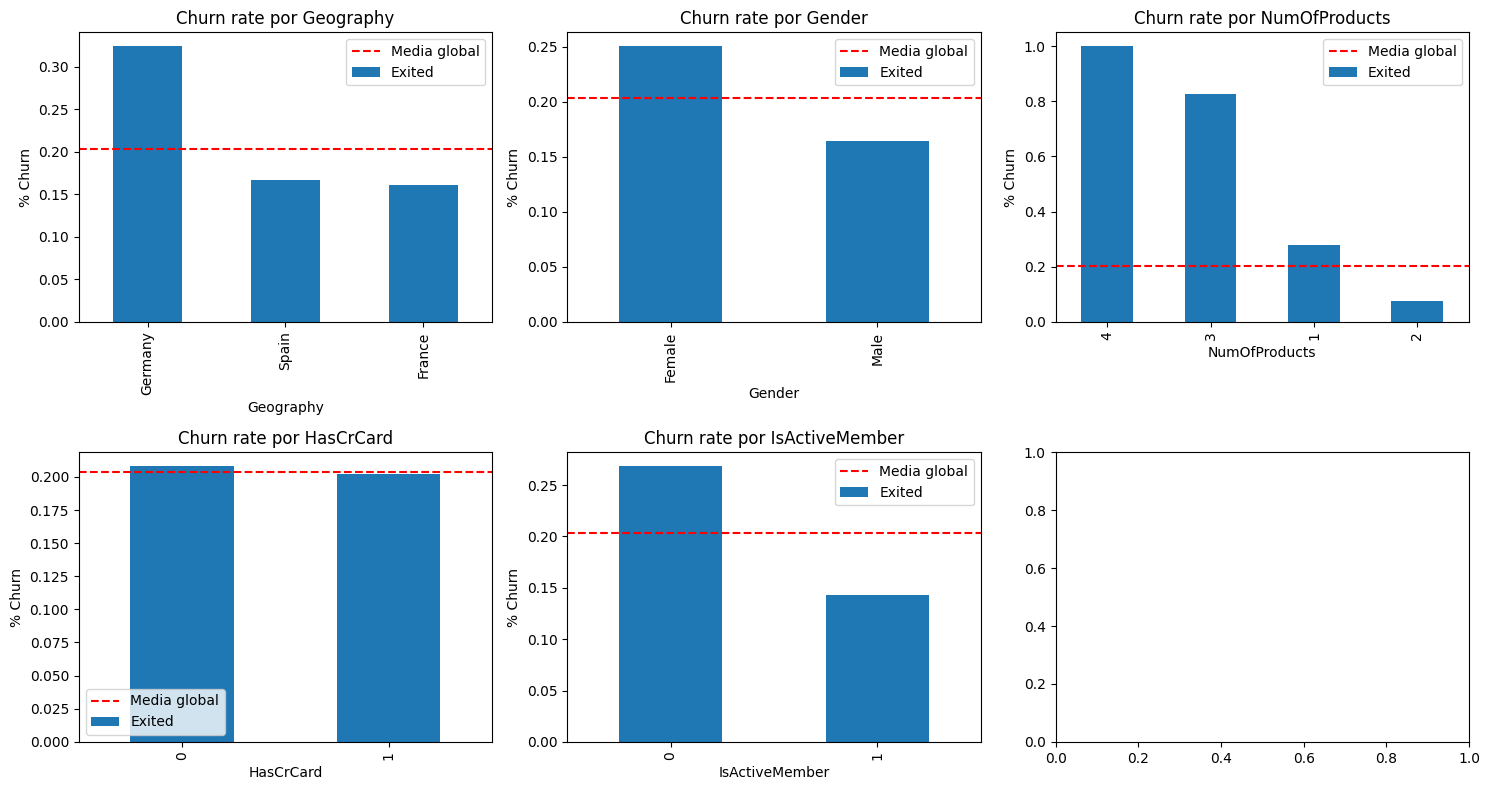

In [ ]:
cat_cols = ['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    churn_rate = bank_df.groupby(col)['Exited'].mean().sort_values(ascending=False)
    churn_rate.plot(kind='bar', ax=axes[i])
    axes[i].set_title(f'Churn rate por {col}')
    axes[i].set_ylabel('% Churn')
    #media de exited un 20%
    axes[i].axhline(bank_df['Exited'].mean(), color='red', linestyle='--', label='Media global')
    axes[i].legend()
plt.tight_layout()
plt.show()

**NumOfProducts** Prácticamente todo el que tiene 3 o 4 productos se va.

1 producto: ~28% churn (ligeramente por encima de la media).

2 productos: ~8% churn — el grupo con menos churn de todos.

3 productos: ~83% churn 🔴

4 productos: 100% churn 🔴

**IsActiveMember** un cliente que usa activamente sus productos está más "enganchado" y es menos probable que se vaya.

Inactivos (0): ~27% churn.

Activos (1): ~14% churn.

**Geography**

Alemania: ~32% churn, muy por encima de la media (0.20).

**Gender**

Mujeres: ~25% churn.
Hombres: ~16% churn.

In [ ]:
bank_df['NumOfProducts'].value_counts()

,count
NumOfProducts,
1,5084
2,4590
3,266
4,60


grupos de "3" y "4" productos son muy pequeños (266 + 60 = 326 clientes, solo el 3.3% del dataset total). El 100% y 83% de churn para esos productos es real pero está basado en pocas muestras.

OJO que el modelo no la use como atajo. Vigilar que no memorice.

## Matriz de correlación (solo numéricas)

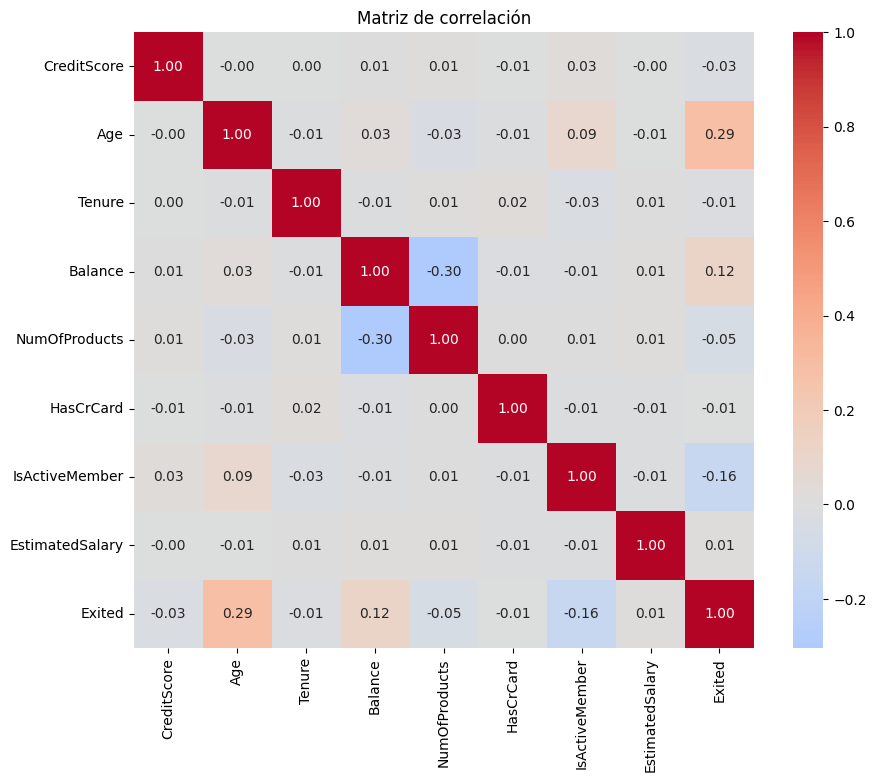

In [ ]:
plt.figure(figsize=(10, 8))
corr = bank_df.select_dtypes(include=['int64', 'float64']).corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlación')
plt.show()

**Age y Balance** variables más fuertes.

--> **Numofproducts** relacion casi negativa, pero en el gráfico anterior vimos fuerte correlación--> No es contradicción, es debido a que la matriz de correlacion solo detecta relaciones lineales, y el patron de products no es lineal o constante.

Un modelo lineal como reg logistica no sería muy adecuado en este caso.

**multicolinealidad**:
Balance y NumOfProducts tienen correlación de -0.30 entre sí. clientes con más productos tienden a tener menos balance en la cuenta principal.

##Variable nueva "haszerobalance"

In [ ]:
bank_df['HasZeroBalance'] = (bank_df['Balance'] == 0).astype(int)
print(bank_df.groupby('HasZeroBalance')['Exited'].mean())

HasZeroBalance
0    0.240796
1    0.138236
Name: Exited, dtype: float64


los clientes con balance cero tienen casi la mitad de churn que los que sí tienen saldo.

## Relación numofproducts y isactivemember

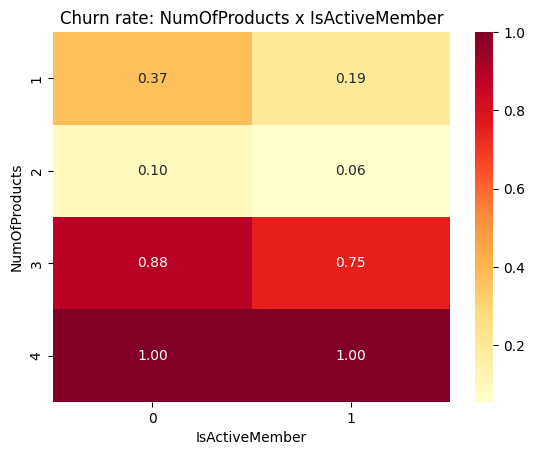

In [ ]:
pivot = bank_df.pivot_table(values='Exited', index='NumOfProducts', columns='IsActiveMember', aggfunc='mean')
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlOrRd')
plt.title('Churn rate: NumOfProducts x IsActiveMember')
plt.show()


Estar activo reduce el churn en cada nivel de producto, pero no lo elimina en los niveles altos de riesgo. Isactivemember actúa como un modulador secundario.

interaccion no lineal

## Nueva variable ProductRisk

In [ ]:
bank_df['ProductRisk'] = bank_df['NumOfProducts'].map({1: 'Low', 2: 'Low', 3: 'High', 4: 'High'})
bank_df.groupby('ProductRisk')['Exited'].mean()

,Exited
ProductRisk,
High,0.858896
Low,0.181621


## Conclusión EDA inicial:

Fuertes: Age, NumOfProducts (no lineal), ProductRisk (nueva — probablemente aún más robusta que NumOfProducts al agrupar los niveles de riesgo con pocos datos), IsActiveMember, Geography

Moderadas: Balance, HasZeroBalance (nueva — diferencia clara de 24% vs 14% churn), Gender

Débiles/nulas: CreditScore, Tenure, EstimatedSalary, HasCrCard


# Encoding categorical features

In [ ]:
bank_df

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,HasZeroBalance,ProductRisk
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,Low
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0,Low
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,0,High
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,1,Low
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64,0,1,Low
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,0,Low
9997,709,France,Female,36,7,0.00,1,0,1,42085.58,1,1,Low
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,0,Low


In [ ]:
# 1. Encoding binario simple para variables con solo 2 categorías
bank_df['Gender']=bank_df['Gender'].map({'Male':0, 'Female':1})
bank_df['ProductRisk']=bank_df['ProductRisk'].map({'Low':0, 'High':1})

# 2. One-Hot Encoding para Geography (3 categorías sin orden natural)
# (si Germany=0 y Spain=0, ya sabemos que es France, no hace falta esa columna)
bank_df = pd.get_dummies(bank_df, columns=['Geography'], drop_first=True) #True para que la tercera columna se saque de las otras dos

# Convertir a int por claridad (evita que queden como bool)
geo_cols = [col for col in bank_df.columns if col.startswith('Geography_')]
bank_df[geo_cols] = bank_df[geo_cols].astype(int)

print(bank_df.dtypes)
bank_df.head()

CreditScore            int64
Gender                 int64
Age                    int64
Tenure                 int64
Balance              float64
NumOfProducts          int64
HasCrCard              int64
IsActiveMember         int64
EstimatedSalary      float64
Exited                 int64
HasZeroBalance         int64
ProductRisk            int64
Geography_Germany      int64
Geography_Spain        int64
dtype: object


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,HasZeroBalance,ProductRisk,Geography_Germany,Geography_Spain
0,619,1,42,2,0.00,1,1,1,101348.88,1,1,0,0,0
1,608,1,41,1,83807.86,1,0,1,112542.58,0,0,0,0,1
2,502,1,42,8,159660.80,3,1,0,113931.57,1,0,1,0,0
3,699,1,39,1,0.00,2,0,0,93826.63,0,1,0,0,0
4,850,1,43,2,125510.82,1,1,1,79084.10,0,0,0,0,1


# Train/Test split

In [ ]:
from sklearn.model_selection import train_test_split

# Split para entrenar el modelo de ML ######################################
# Separamos features (X) y target (y)
X = bank_df.drop(columns=['Exited'])
y = bank_df['Exited']

# Split estratificado: mantiene la proporción ~80/20 de churn en ambos sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,      # reproducibilidad
    stratify=y             # mantiene la proporción de Exited en train y test
)

# Split para el agente del dataset en raw ##################################
X_agent = bank_df_agent.drop(columns=['Exited'])
y_agent = bank_df_agent['Exited']

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_agent, y_agent, test_size=0.2, random_state=42, stratify=y_agent
)
# Verificación: deben coincidir los índices exactamente
assert list(X_train.index) == list(X_train_raw.index)
assert list(X_test.index) == list(X_test_raw.index)

# Verificación: las proporciones deben ser casi idénticas
print("Proporción churn train:", y_train.mean())
print("Proporción churn test:", y_test.mean())
print("Tamaño train:", X_train.shape)
print("Tamaño test:", X_test.shape)

Proporción churn train: 0.20375
Proporción churn test: 0.2035
Tamaño train: (8000, 13)
Tamaño test: (2000, 13)


In [ ]:
#Guardamos las versiones que utilizará el agente
X_train_raw.to_csv('X_train_raw.csv', index=False)
y_train_raw.to_csv('y_train_raw.csv', index=False)
X_test_raw.to_csv('X_test_raw.csv', index=False)
y_test_raw.to_csv('y_test_raw.csv', index=False)

## Escalamos variables

In [ ]:
from sklearn.preprocessing import StandardScaler

# Columnas a escalar
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']

scaler = StandardScaler()

# fit SOLO con train, para evitar data leakage
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])  # solo transform, no fit

# Verificación: en train, media ~0 y std ~1
print(X_train_scaled[num_cols].describe().loc[['mean', 'std']])

# Orden exacto de columnas que verá el modelo (necesario para reordenar
# los datos nuevos en el notebook de agentes antes de predecir)
FEATURE_ORDER = list(X_train_scaled.columns)

       CreditScore           Age        Tenure       Balance  EstimatedSalary
mean -5.728751e-16  2.486900e-16 -9.814372e-17  5.773160e-17    -6.694645e-17
std   1.000063e+00  1.000063e+00  1.000063e+00  1.000063e+00     1.000063e+00


In [ ]:
# Guardo el escalador y el orden de las columnas para usarlo en el sistema agentico
joblib.dump(FEATURE_ORDER, 'feature_order.pkl')
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

#Entrenamiento modelos ML

### Validación cruzada

Para decidir qué modelo usar, comparamos Regresión Logística, Random Forest, XGBoost y LightGBM mediante validación cruzada estratificada **solo sobre `X_train_scaled`/`y_train`**. `X_test`/`y_test` no se usan en esta fase — se reservan para la evaluación final del modelo ya seleccionado y ajustado.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# scale_pos_weight es el equivalente a class_weight='balanced' en XGBoost
# se calcula como: (nº negativos) / (nº positivos) en el train set
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

modelos = {
    'LogisticRegression': LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000),
    'RandomForest': RandomForestClassifier(n_estimators=300, max_depth=8, class_weight='balanced',
                                            random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                              scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                                class_weight='balanced', random_state=42, verbose=-1)
}

# ROC-AUC + PR-AUC como métricas principales; PR-AUC es más informativo aquí por el desbalance.
# Recall/precision/F1 de la clase minoritaria (churn) como métricas secundarias.
scoring = ['roc_auc', 'average_precision', 'recall', 'precision', 'f1', 'accuracy']

resultados = []
for nombre, modelo in modelos.items():
    scores = cross_validate(modelo, X_train_scaled, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    resultados.append({
    'modelo': nombre,
    'roc_auc_mean': scores['test_roc_auc'].mean(),
    'roc_auc_std': scores['test_roc_auc'].std(),
    'pr_auc_mean': scores['test_average_precision'].mean(),
    'recall_mean': scores['test_recall'].mean(),
    'precision_mean': scores['test_precision'].mean(),
    'f1_mean': scores['test_f1'].mean(),
    'accuracy_mean': scores['test_accuracy'].mean()
    })


resultados_cross_val_df = pd.DataFrame(resultados).sort_values('pr_auc_mean', ascending=False)
print(resultados_cross_val_df)


               modelo  roc_auc_mean  roc_auc_std  pr_auc_mean  recall_mean  \
3            LightGBM      0.861127     0.014973     0.698973     0.712270   
2             XGBoost      0.859926     0.015898     0.698683     0.712270   
1        RandomForest      0.861471     0.013537     0.688929     0.690798   
0  LogisticRegression      0.831037     0.015172     0.602155     0.747239   

   precision_mean   f1_mean  accuracy_mean  
3        0.530968  0.608021       0.813000  
2        0.534128  0.609993       0.814750  
1        0.545223  0.608821       0.819375  
0        0.450757  0.562049       0.762875  


Random Forest, LightGBM y XGBoost muestran un rendimiento muy similar en validación cruzada. Antes de decidir cuál de los tres seleccionar, comprobamos si la diferencia observada en PR-AUC es estadísticamente significativa o simplemente ruido entre folds, mediante un **test de Wilcoxon pareado** (usando el mismo objeto `cv`, para que la comparación se haga fold a fold).

In [ ]:
from scipy.stats import wilcoxon
from sklearn.model_selection import cross_val_score

# Recalculamos las puntuaciones por fold (PR-AUC) para RF, LightGBM y XGBoost,
# usando el MISMO objeto cv (mismos folds) para que la comparación sea pareada.
pr_auc_rf = cross_val_score(modelos['RandomForest'], X_train_scaled, y_train,
                             cv=cv, scoring='average_precision', n_jobs=-1)
pr_auc_lgbm = cross_val_score(modelos['LightGBM'], X_train_scaled, y_train,
                               cv=cv, scoring='average_precision', n_jobs=-1)
pr_auc_xgb = cross_val_score(modelos['XGBoost'], X_train_scaled, y_train,
                              cv=cv, scoring='average_precision', n_jobs=-1)

print("PR-AUC por fold:")
print("RandomForest:", pr_auc_rf)
print("LightGBM:    ", pr_auc_lgbm)
print("XGBoost:     ", pr_auc_xgb)

# Test de Wilcoxon (no paramétrico, apropiado para 10 folds pareados)
stat_lgbm, p_lgbm = wilcoxon(pr_auc_rf, pr_auc_lgbm)
stat_xgb, p_xgb = wilcoxon(pr_auc_rf, pr_auc_xgb)
stat_lgbm_xgb, p_lgbm_xgb = wilcoxon(pr_auc_lgbm, pr_auc_xgb)

print(f"\nRandomForest vs LightGBM -> estadístico={stat_lgbm:.4f}, p-valor={p_lgbm:.4f}")
print(f"RandomForest vs XGBoost  -> estadístico={stat_xgb:.4f}, p-valor={p_xgb:.4f}")
print(f"LightGBM vs XGBoost      -> estadístico={stat_lgbm_xgb:.4f}, p-valor={p_lgbm_xgb:.4f}")

# Conclusión conjunta de las tres comparaciones
print("\nConclusión:")

if p_lgbm > 0.05 and p_xgb > 0.05:
    print("- No hay diferencia estadísticamente significativa (p > 0.05) en PR-AUC "
          "entre Random Forest y los otros dos modelos.")
else:
    if p_lgbm <= 0.05:
        mejor = "LightGBM" if pr_auc_lgbm.mean() > pr_auc_rf.mean() else "RandomForest"
        print(f"- Diferencia significativa entre RandomForest y LightGBM (p={p_lgbm:.4f}); "
              f"{mejor} obtiene un PR-AUC medio superior.")
    if p_xgb <= 0.05:
        mejor = "XGBoost" if pr_auc_xgb.mean() > pr_auc_rf.mean() else "RandomForest"
        print(f"- Diferencia significativa entre RandomForest y XGBoost (p={p_xgb:.4f}); "
              f"{mejor} obtiene un PR-AUC medio superior.")

if p_lgbm_xgb > 0.05:
    print(f"- Entre LightGBM y XGBoost no hay diferencia estadísticamente significativa "
          f"(p={p_lgbm_xgb:.4f}), por lo que ambos modelos de boosting son equivalentes "
          f"en rendimiento sobre este conjunto de datos.")
else:
    mejor_boost = "LightGBM" if pr_auc_lgbm.mean() > pr_auc_xgb.mean() else "XGBoost"
    print(f"- Entre LightGBM y XGBoost sí hay diferencia estadísticamente significativa "
          f"(p={p_lgbm_xgb:.4f}); {mejor_boost} obtiene un PR-AUC medio superior "
          f"(LightGBM={pr_auc_lgbm.mean():.4f}, XGBoost={pr_auc_xgb.mean():.4f}).")

# Modelo con mejor PR-AUC medio
resultados_medios = {
    'RandomForest': pr_auc_rf.mean(),
    'LightGBM': pr_auc_lgbm.mean(),
    'XGBoost': pr_auc_xgb.mean()
}
mejor_modelo = max(resultados_medios, key=resultados_medios.get)

print(f"\nEn conjunto, el modelo con mejor PR-AUC medio es: {mejor_modelo} "
      f"(PR-AUC medio = {resultados_medios[mejor_modelo]:.4f})")

PR-AUC por fold:
RandomForest: [0.65865964 0.70669609 0.73516809 0.68510285 0.68851588 0.73178774
 0.67913683 0.66060918 0.66103295 0.68257977]
LightGBM:     [0.67716629 0.72340513 0.73641151 0.71277255 0.71550364 0.74093175
 0.67298737 0.67078202 0.66056256 0.67920426]
XGBoost:      [0.6856433  0.72176232 0.7340734  0.70352679 0.72061254 0.74132535
 0.67379166 0.67423041 0.65205091 0.679812  ]

RandomForest vs LightGBM -> estadístico=8.0000, p-valor=0.0488
RandomForest vs XGBoost  -> estadístico=10.0000, p-valor=0.0840
LightGBM vs XGBoost      -> estadístico=27.0000, p-valor=1.0000

Conclusión:
- Diferencia significativa entre RandomForest y LightGBM (p=0.0488); LightGBM obtiene un PR-AUC medio superior.
- Entre LightGBM y XGBoost no hay diferencia estadísticamente significativa (p=1.0000), por lo que ambos modelos de boosting son equivalentes en rendimiento sobre este conjunto de datos.

En conjunto, el modelo con mejor PR-AUC medio es: LightGBM (PR-AUC medio = 0.6990)


- **Random Forest vs LightGBM → p = 0.0488** (significativo, p < 0.05). LightGBM presenta un PR-AUC consistentemente superior a Random Forest (0.699 frente a 0.689).
- **Random Forest vs XGBoost → p = 0.0840** (no significativo). Random Forest y XGBoost quedan en empate técnico.

Se descarta por tanto la hipótesis inicial de que las diferencias en PR-AUC eran ruido: en el caso de LightGBM, la diferencia es estadísticamente significativa. Además, esta ventaja no es solo estadística sino también relevante para el caso de uso: LightGBM obtiene mayor recall que Random Forest (0.712 frente a 0.691), con una precisión y un F1 prácticamente idénticos. Dado que en un sistema de retención el coste de un falso negativo (no detectar a un cliente que va a abandonar) es normalmente mayor que el de un falso positivo (contactar a alguien que no iba a irse), el mayor recall de LightGBM es una ventaja alineada con el objetivo de negocio, no solo con la métrica de selección.

**Se selecciona LightGBM** como modelo final: gana con significancia estadística a Random Forest en PR-AUC, mejora el recall sin penalizar precisión/F1, y está en empate técnico con XGBoost (por lo que no hay motivo para preferir XGBoost en su lugar).

## Entrenamiento de los modelos para entender a qué features dan importancia

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay, average_precision_score
import matplotlib.pyplot as plt

### Logistic regression

In [ ]:
from sklearn.linear_model import LogisticRegression

# Entrenamos con class_weight='balanced' para compensar el desbalance de clases
log_reg = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [ ]:
coef_df = pd.DataFrame({
    'feature': X_train_scaled.columns,
    'coefficient': log_reg.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)

print(coef_df)

              feature  coefficient
10        ProductRisk     5.872821
5       NumOfProducts    -1.448000
11  Geography_Germany     0.964048
7      IsActiveMember    -0.909478
2                 Age     0.766703
1              Gender     0.542336
9      HasZeroBalance     0.198917
6           HasCrCard    -0.116091
12    Geography_Spain     0.101749
4             Balance     0.101293
0         CreditScore    -0.085189
8     EstimatedSalary     0.041734
3              Tenure    -0.021276


Los coeficientes obtenidos con ProductRisk y NumOfProducts juntos en el modelo no son interpretables: ambas variables están altamente correlacionadas entre sí (ProductRisk se deriva directamente de NumOfProducts), lo que genera multicolinealidad e inestabilidad en sus coeficientes individuales (signos contradictorios: ProductRisk +5.87 vs NumOfProducts -1.45).

Además, NumOfProducts tiene una relación no lineal con el churn (8% en 2 productos, pero 83-100% en 3-4 productos), que un modelo lineal como la regresión logística no puede capturar bien con un único coeficiente — por eso se creó ProductRisk, que agrupa esa relación en dos niveles (bajo/alto riesgo) y sí es representable linealmente.

In [ ]:
X_train_v2 = X_train_scaled.drop(columns=['NumOfProducts'])

log_reg_v2 = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
log_reg_v2.fit(X_train_v2, y_train)

coef_df_v2 = pd.DataFrame({
    'feature': X_train_v2.columns,
    'coefficient': log_reg_v2.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)
print(coef_df_v2)

              feature  coefficient
9         ProductRisk     3.205314
6      IsActiveMember    -0.930215
2                 Age     0.798580
10  Geography_Germany     0.774962
1              Gender     0.512903
8      HasZeroBalance    -0.217841
4             Balance     0.121270
5           HasCrCard    -0.096280
0         CreditScore    -0.083322
11    Geography_Spain     0.068650
3              Tenure    -0.032356
7     EstimatedSalary     0.027320


Al eliminar NumOfProducts y quedarnos solo con ProductRisk, los coeficientes resultantes son coherentes con el EDA (Age, IsActiveMember, Geography_Germany y ProductRisk como variables más influyentes, todas con el signo esperado). Este es el trade-off habitual entre interpretabilidad y rendimiento puro: para el modelo final priorizado en rendimiento, un modelo no lineal (Random Forest/XGBoost) podría usar ambas variables sin este problema, ya que no depende de coeficientes lineales.

### Random Forest

Ensamble de árboles de decisión por *bagging* (cada árbol se entrena sobre una muestra aleatoria de los datos y de las variables, y se promedian sus resultados). No depende de la escala de las variables y no sufre el problema de multicolinealidad de los modelos lineales, por lo que aquí sí usamos el dataset completo (con NumOfProducts y ProductRisk juntas).

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Usamos la versión con TODAS las variables (incluyendo NumOfProducts y ProductRisk juntas)
# Los árboles no tienen problema de multicolinealidad como los modelos lineales
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,              # evita overfitting, empezamos moderado
    class_weight='balanced',  # por el desbalanceo de clases
    random_state=42,
    n_jobs=-1                 # usa todos los cores disponibles
)

rf.fit(X_train_scaled, y_train)


RandomForestClassifier(class_weight='balanced', max_depth=8, n_estimators=300,
                       n_jobs=-1, random_state=42)

              feature  importance
2                 Age    0.342875
5       NumOfProducts    0.215881
4             Balance    0.079557
10        ProductRisk    0.078771
7      IsActiveMember    0.058284
11  Geography_Germany    0.052278
8     EstimatedSalary    0.045634
0         CreditScore    0.045273
3              Tenure    0.025382
9      HasZeroBalance    0.022482
1              Gender    0.019569
12    Geography_Spain    0.008065
6           HasCrCard    0.005949


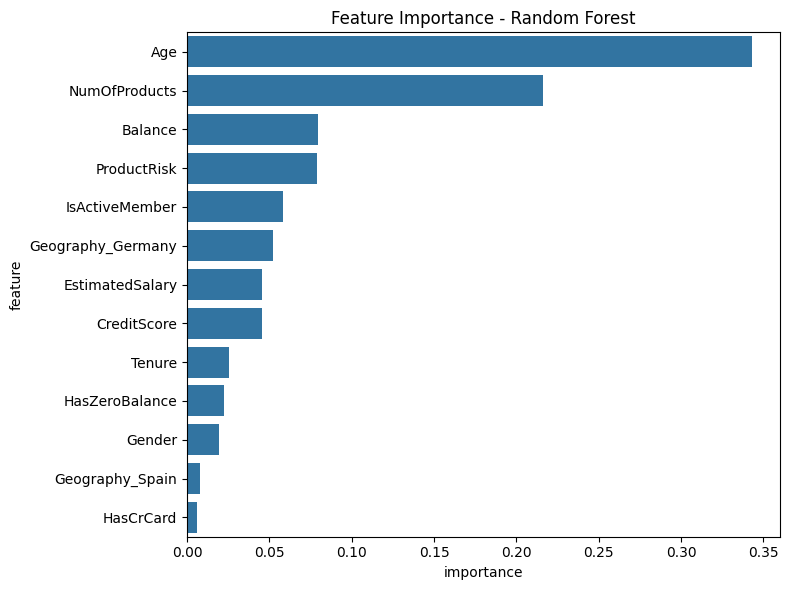

In [ ]:
importance_df = pd.DataFrame({
    'feature': X_train_scaled.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print(importance_df)

plt.figure(figsize=(8, 6))
sns.barplot(data=importance_df, x='importance', y='feature')
plt.title('Feature Importance - Random Forest')
plt.tight_layout()
plt.show()

### XGBoost

Ennsamble de árboles por boosting: en vez de entrenar los árboles en paralelo como Random Forest, los entrena en secuencia, donde cada árbol nuevo intenta corregir los errores de los anteriores. Suele capturar mejor relaciones no lineales como las que vimos con NumOfProducts.

In [ ]:
from xgboost import XGBClassifier

# scale_pos_weight es el equivalente a class_weight='balanced' en XGBoost
# se calcula como: (nº negativos) / (nº positivos) en el train set
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", scale_pos_weight)

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss'
)

xgb.fit(X_train_scaled, y_train)


importance_xgb = pd.DataFrame({
    'feature': X_train_scaled.columns,
    'importance': xgb.feature_importances_
}).sort_values('importance', ascending=False)
print(importance_xgb)

scale_pos_weight: 3.9079754601226995
              feature  importance
5       NumOfProducts    0.230492
9      HasZeroBalance    0.150549
7      IsActiveMember    0.141951
2                 Age    0.137509
11  Geography_Germany    0.088283
1              Gender    0.061173
4             Balance    0.051443
12    Geography_Spain    0.038017
0         CreditScore    0.028828
8     EstimatedSalary    0.027955
3              Tenure    0.026742
6           HasCrCard    0.017059
10        ProductRisk    0.000000


### LightGBM

También boosting de árboles como XGBoost, pero con una estrategia de crecimiento distinta: en vez de crecer nivel a nivel, LightGBM crece los árboles hoja a hoja (elige siempre la hoja que más reduce el error). Suele ser más rápido y competitivo en rendimiento en datasets como este (tamaño pequeño/medio).

In [ ]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    class_weight='balanced',  # LightGBM sí soporta este parámetro directamente
    random_state=42,
    verbose=-1,  # silencia logs internos
    importance_type='gain'   # cambia el criterio de importancia
)

lgbm.fit(X_train_scaled, y_train)

importance_lgbm = pd.DataFrame({
    'feature': X_train_scaled.columns,
    'importance': lgbm.feature_importances_
}).sort_values('importance', ascending=False)
print(importance_lgbm)

              feature    importance
2                 Age  20007.218552
5       NumOfProducts  13255.337463
4             Balance   8248.476031
8     EstimatedSalary   4844.068179
0         CreditScore   4674.889820
7      IsActiveMember   3621.638711
11  Geography_Germany   2594.870339
3              Tenure   1944.085146
1              Gender   1095.166606
12    Geography_Spain    588.485706
6           HasCrCard    204.355147
9      HasZeroBalance     38.351234
10        ProductRisk      4.991150


## LightGBM hyperparameter tuning

Una vez elegido LightGBM como modelo final, buscamos la combinación de hiperparámetros que maximiza el PR-AUC mediante RandomizedSearchCV, usando el mismo cv de 10 folds que en la fase de selección de modelo para que los resultados sean comparables.

In [ ]:
# # tarda bastante en ejecutar, la comento tras encontrar los mejores hiperparámetros
# from sklearn.model_selection import RandomizedSearchCV
# from lightgbm import LGBMClassifier

# param_dist = {
#     'n_estimators': [200, 300, 400, 600, 800],
#     'num_leaves': [15, 31, 63, 127],
#     'max_depth': [-1, 4, 6, 8, 10],
#     'learning_rate': [0.01, 0.03, 0.05, 0.08, 0.1],
#     'min_child_samples': [5, 10, 20, 30, 50],
#     'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
#     'subsample_freq': [1, 5, 10],   # necesario para que 'subsample' tenga efecto real
#     'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
#     'reg_alpha': [0, 0.01, 0.1, 0.5, 1.0],
#     'reg_lambda': [0, 0.01, 0.1, 0.5, 1.0],
# }

# lgbm_base = LGBMClassifier(class_weight='balanced', random_state=42, verbose=-1)

# search_lgbm = RandomizedSearchCV(
#     estimator=lgbm_base,
#     param_distributions=param_dist,
#     n_iter=50,
#     scoring='average_precision',   # coherente con el criterio de selección de modelo
#     cv=cv,                          # mismo StratifiedKFold(n_splits=10) que en la comparación
#     random_state=42,
#     n_jobs=-1,
#     verbose=1
# )

# search_lgbm.fit(X_train_scaled, y_train)
# print("Mejores hiperparámetros:", search_lgbm.best_params_)
# print("Mejor PR-AUC (CV):", search_lgbm.best_score_)


Fitting 10 folds for each of 50 candidates, totalling 500 fits
Mejores hiperparámetros: {'subsample_freq': 10, 'subsample': 0.7, 'reg_lambda': 0, 'reg_alpha': 0.5, 'num_leaves': 127, 'n_estimators': 600, 'min_child_samples': 30, 'max_depth': 6, 'learning_rate': 0.01, 'colsample_bytree': 0.6}
Mejor PR-AUC (CV): 0.7044922386328624


In [ ]:
from lightgbm import LGBMClassifier

# Recreamos el modelo directamente con los mejores hiperparámetros encontrados
best_lgbm = LGBMClassifier(
    # sustituir estos valores por los de search_lgbm.best_params_
    n_estimators=600,
    num_leaves=127,
    max_depth=6,
    learning_rate=0.01,
    min_child_samples=30,
    subsample=0.7,
    subsample_freq = 10,
    colsample_bytree=0.6,
    reg_alpha=0.5,
    reg_lambda=0.0,
    class_weight='balanced',
    random_state=42,
    verbose=-1
)

best_lgbm.fit(X_train_scaled, y_train)


LGBMClassifier(class_weight='balanced', colsample_bytree=0.6,
               learning_rate=0.01, max_depth=6, min_child_samples=30,
               n_estimators=600, num_leaves=127, random_state=42, reg_alpha=0.5,
               subsample=0.7, subsample_freq=10, verbose=-1)

              precision    recall  f1-score   support

           0       0.93      0.83      0.88      1593
           1       0.53      0.74      0.62       407

    accuracy                           0.81      2000
   macro avg       0.73      0.79      0.75      2000
weighted avg       0.85      0.81      0.83      2000

ROC-AUC: 0.8654771875110858
PR-AUC: 0.7163136941506724


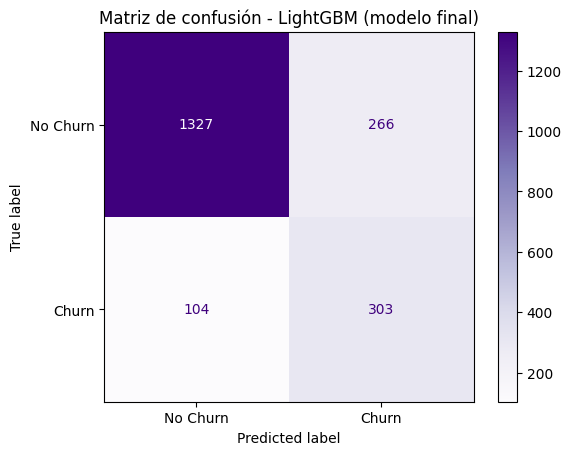

In [ ]:
# Única evaluación sobre test, ahora que el modelo está seleccionado y ajustado
y_pred_best = best_lgbm.predict(X_test_scaled)
y_pred_proba_best = best_lgbm.predict_proba(X_test_scaled)[:, 1]

print(classification_report(y_test, y_pred_best))
print("ROC-AUC:", roc_auc_score(y_test, y_pred_proba_best))
print("PR-AUC:", average_precision_score(y_test, y_pred_proba_best))

cm_best = confusion_matrix(y_test, y_pred_best)
disp_best = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=['No Churn', 'Churn'])
disp_best.plot(cmap='Purples')
plt.title('Matriz de confusión - LightGBM (modelo final)')
plt.show()


Se evaluó la posibilidad de ajustar el umbral de decisión dado el desbalance FN/FP, pero se considera que el coste de un falso positivo (contactar a un cliente que no iba a irse) también es relevante para el negocio, no solo el de un falso negativo, por lo que se mantiene el umbral estándar de 0.5

Modelo más equilibrado para una mejor predicción.

In [ ]:
#guardamos el modelo
joblib.dump(best_lgbm, 'best_model_lgbm.pkl')

['best_model_lgbm.pkl']

In [ ]:
predicciones_best_lgbm = pd.DataFrame({
    'index': X_test.index,
    'pred_original': y_test.values,
    'pred_proba': y_pred_proba_best,
    'pred_clase': y_pred_best
})
predicciones_best_lgbm.to_csv('predicciones_best_lgbm.csv', index=False)
predicciones_best_lgbm.head()


,index,pred_original,pred_proba,pred_clase
0,5702,0,0.060651,0
1,3667,0,0.197019,0
2,1617,0,0.122804,0
3,5673,0,0.143398,0
4,4272,0,0.258557,0


In [ ]:
#Guardamos las versiones utilizadaS
!pip freeze | grep -iE "lightgbm|scikit-learn|joblib|pandas|numpy|scipy" > requirements_agente.txt